# Federated Random Forest — Give Me Some Credit

Notebook thực nghiệm local theo **Protocol v1.0**: 60% train, 20% validation, 20% test; 5 client × 20 cây, một vòng ghép rừng. Centralized 100 cây dùng cùng train, validation, test và tham số. Đây là mô phỏng local; việc chạy SuperLink/SuperNode trên Azure cần thực hiện riêng. Không có dữ liệu bản ghi train được chuyển cho hàm aggregation trong luồng thí nghiệm này; bước chuẩn bị dữ liệu vẫn tập trung.

Chạy từ thư mục repository bằng **Run All**. Đặt `SOURCE_CSV` và `PROJECT_ROOT` nếu môi trường khác. Cần `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `nbformat` và mã trong `flower-app/fl_app`.

## 1. Cấu hình và giao thức

In [1]:
from pathlib import Path
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "flower-app" / "fl_app").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SOURCE_CSV = PROJECT_ROOT / "data" / "cs-training.csv"
DATA_ROOT = PROJECT_ROOT / "data" / "experiments"
RESULT_ROOT = PROJECT_ROOT / "results" / "protocol_v1"
SEED = 42
N_CLIENTS = 5
TREES_PER_CLIENT = 20
MODE = "iid"  # "non-iid" là phép thử riêng; dùng ALPHA khi chọn chế độ này.
ALPHA = 0.5
MIN_RECALL = 0.30
RF_CONFIG = dict(max_depth=10, min_samples_leaf=5, max_features="sqrt", class_weight=None)
sys.path.insert(0, str(PROJECT_ROOT / "flower-app"))
from fl_app.protocol import (TARGET, ROW_ID, prepare_split, partition_train, read_checked,
                             sha256)
from fl_app.tree_codec import encode_forest, decode_forests, schema_hash
print("Source:", SOURCE_CSV)
print("RF:", RF_CONFIG)

Source: C:\Users\ACER\Documents\ChatGPT\Project Cloud\data\cs-training.csv
RF: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None}


## 2. Tạo split và phân vùng Client

Median chỉ học từ Train 90.000 dòng. Giữ nội dung trùng nhưng source row ID không được trùng giữa các tập. Các file/manifest là đầu vào có thể cấp riêng cho từng VM; không đưa Validation/Test cho Client.

In [2]:
split_dir = prepare_split(SOURCE_CSV, DATA_ROOT, SEED)
partition_dir = partition_train(split_dir, MODE, ALPHA, N_CLIENTS, SEED)
schema = json.loads((split_dir / "feature_schema.json").read_text(encoding="utf-8"))
manifest = json.loads((split_dir / "split_metadata.json").read_text(encoding="utf-8"))
partition_summary = json.loads((partition_dir / "summary.json").read_text(encoding="utf-8"))
train = read_checked(split_dir / "train.csv", schema)
validation = read_checked(split_dir / "validation.csv", schema)
test = read_checked(split_dir / "test.csv", schema)
clients = [read_checked(partition_dir / f"client_{i}.csv", schema) for i in range(1, N_CLIENTS + 1)]
assert sum(len(frame) for frame in clients) == len(train)
assert set().union(*(set(frame[ROW_ID]) for frame in clients)) == set(train[ROW_ID])
assert all(set(clients[i][ROW_ID]).isdisjoint(clients[j][ROW_ID])
           for i in range(N_CLIENTS) for j in range(i + 1, N_CLIENTS))
assert set(train[ROW_ID]).isdisjoint(validation[ROW_ID])
assert set(train[ROW_ID]).isdisjoint(test[ROW_ID])
assert set(validation[ROW_ID]).isdisjoint(test[ROW_ID])
assert manifest["source_sha256"] == sha256(SOURCE_CSV)
assert all(manifest["split_sha256"][name] == sha256(split_dir / f"{name}.csv")
           for name in ("train", "validation", "test"))
assert all(item["sha256"] == sha256(partition_dir / f"client_{item['client_id']}.csv")
           for item in partition_summary["clients"])
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "rows": [len(train), len(validation), len(test)],
                      "positive_rate": [frame[TARGET].mean() for frame in (train, validation, test)]}))
display(pd.DataFrame(partition_summary["clients"]))
print("source_sha256:", manifest["source_sha256"])
print("feature_schema_sha256:", manifest["feature_schema_sha256"])
print("split_dir:", split_dir)

source_sha256: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac
feature_schema_sha256: b9fe26947dc3e3c8ef1a815d4741bc784122841c41432eb81cf2522c0823125b
split_dir: C:\Users\ACER\Documents\ChatGPT\Project Cloud\data\experiments\split_seed_42


        split   rows  positive_rate
0       train  90000       0.066844
1  validation  30000       0.066833
2        test  30000       0.066833

   client_id   rows  positive_rows                                                            sha256
0          1  18001           1204  8fb4fabacfdf1f8ca784e2cd9051178facf40f57abc4cf4cae351a6a1c812e37
1          2  18000           1203  2434a62f93701f63c084d9e8a726fcae31556da7b459c7969de681499ec1a63e
2          3  18000           1203  9f0f8a7559110d707e5e304f0a4c77e0c2441a7d4c661ad39fba7bd5236b025b
3          4  18000           1203  ae4b2e6843429f7da9eaf04da5480fc212d137384b0a853fc9341b7bc1c6a8d4
4          5  17999           1203  e2c8f894119a87eef327e526d792b935fff29e6a87a53c7ffeb2911a76a3e3d7

## 3. Huấn luyện Centralized và Client

Centralized dùng 100 cây trên cùng Train. Mỗi Client chỉ đọc partition của mình và fit 20 cây. Random seed từng Client khác nhau nhưng cấu hình RF như nhau.

In [3]:
features = schema["features"]
start = time.perf_counter()
central = RandomForestClassifier(n_estimators=N_CLIENTS * TREES_PER_CLIENT,
                                 random_state=SEED, n_jobs=-1, **RF_CONFIG)
central.fit(train[features], train[TARGET])
central_seconds = time.perf_counter() - start
payloads, client_log = [], []
for client_id, frame in enumerate(clients, 1):
    start = time.perf_counter()
    model = RandomForestClassifier(n_estimators=TREES_PER_CLIENT,
                                   random_state=SEED + client_id, n_jobs=-1, **RF_CONFIG)
    model.fit(frame[features], frame[TARGET])
    payload = encode_forest(model)
    recovered = decode_forests([payload], features)
    sample = validation[features].iloc[:50]
    assert np.allclose(model.predict_proba(sample), recovered.predict_proba(sample.to_numpy()), atol=1e-10)
    payloads.append(payload)
    client_log.append({"client_id": client_id, "rows": len(frame),
                       "positive_rate": float(frame[TARGET].mean()),
                       "train_seconds": time.perf_counter() - start,
                       "numeric_payload_bytes": sum(array.nbytes for array in payload.values()),
                       "trees": len(model.estimators_)})
display(pd.DataFrame(client_log))
print("Centralized train seconds:", round(central_seconds, 2))

Centralized train seconds: 3.41


   client_id   rows  positive_rate  train_seconds  numeric_payload_bytes  trees
0          1  18001       0.066885       0.223102                 385248     20
1          2  18000       0.066833       0.222806                 400032     20
2          3  18000       0.066833       0.216398                 399168     20
3          4  18000       0.066833       0.210101                 374688     20
4          5  17999       0.066837       0.203432                 414528     20

## 4. Ghép cây và kiểm tra payload

Aggregation chỉ nhận numeric tree payload; không nhận DataFrame/CSV của Client. Tổng cây là 100. Numeric payload bytes là kích thước mảng, **chưa phải byte mạng thực đo**. Model artifact vẫn có nguy cơ rò rỉ thông tin; đây không phải differential privacy.

In [4]:
assert all(len(payload) == TREES_PER_CLIENT * 5 for payload in payloads)
forest = decode_forests(payloads, features)
assert len(forest.trees) == N_CLIENTS * TREES_PER_CLIENT
probe = validation[features].iloc[:25]
for payload, frame in zip(payloads, clients):
    assert len(payload) == TREES_PER_CLIENT * 5
for scores in (central.predict_proba(probe)[:, 1], forest.predict_proba(probe.to_numpy())[:, 1]):
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
payload_bytes = sum(row["numeric_payload_bytes"] for row in client_log)
print("Global trees:", len(forest.trees), "numeric payload bytes:", payload_bytes)
print("Schema hash used in Flower messages:", schema_hash(features))

Global trees: 100 numeric payload bytes: 1973664
Schema hash used in Flower messages: 82b63ec1c5d8936f98ecf73807f9160def1f74a54be58ac07cd676ac5db60793


## 5. Chọn ngưỡng trên Validation

Mỗi mô hình chọn ngưỡng F1 trên cùng validation; thêm ngưỡng ưu tiên precision với recall ít nhất 30%. Không dùng Test để chọn tham số hoặc ngưỡng.

In [5]:
def choose_thresholds(labels, scores):
    precision, recall, candidate = precision_recall_curve(labels, scores)
    p, r = precision[:-1], recall[:-1]
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    eligible = np.flatnonzero(r >= MIN_RECALL)
    if not len(eligible):
        raise ValueError("No threshold meets minimum recall")
    precision_choice = max(eligible, key=lambda i: (p[i], r[i]))
    return {"default": 0.5, "best_f1": float(candidate[np.argmax(f1)]),
            "precision_at_recall": float(candidate[precision_choice])}

def metrics(labels, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {"threshold": threshold, "precision": precision_score(labels, predicted, zero_division=0),
            "recall": recall_score(labels, predicted, zero_division=0),
            "f1": f1_score(labels, predicted, zero_division=0),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

models = {"centralized": central, "federated": forest}
def probabilities(model, frame):
    values = frame[features] if model is central else frame[features].to_numpy()
    return model.predict_proba(values)[:, 1]
thresholds = {}
validation_rows = []
for name, model in models.items():
    scores = probabilities(model, validation)
    thresholds[name] = choose_thresholds(validation[TARGET], scores)
    for policy, threshold in thresholds[name].items():
        validation_rows.append({"model": name, "policy": policy,
                                "average_precision": average_precision_score(validation[TARGET], scores),
                                **metrics(validation[TARGET], scores, threshold)})
display(pd.DataFrame(validation_rows).round(4))

         model               policy  average_precision  threshold  precision  recall      f1     tn    fp    fn   tp
0  centralized              default             0.3835     0.5000     0.5978  0.1646  0.2581  27773   222  1675  330
1  centralized              best_f1             0.3835     0.2475     0.4257  0.4429  0.4341  26797  1198  1117  888
2  centralized  precision_at_recall             0.3835     0.3662     0.5114  0.3022  0.3799  27416   579  1399  606
3    federated              default             0.3884     0.5000     0.6097  0.1511  0.2422  27801   194  1702  303
4    federated              best_f1             0.3884     0.2149     0.4039  0.4798  0.4386  26575  1420  1043  962
5    federated  precision_at_recall             0.3884     0.3628     0.5167  0.3007  0.3802  27431   564  1402  603

## 6. Đánh giá cuối trên Test chung

         model               policy  average_precision  roc_auc  threshold  precision  recall      f1     tn    fp    fn   tp
0  centralized              default             0.4034   0.8668     0.5000     0.6004  0.1566  0.2484  27786   209  1691  314
1  centralized              best_f1             0.4034   0.8668     0.2475     0.4285  0.4529  0.4403  26784  1211  1097  908
2  centralized  precision_at_recall             0.4034   0.8668     0.3662     0.5116  0.2973  0.3760  27426   569  1409  596
3    federated              default             0.4074   0.8669     0.5000     0.6186  0.1496  0.2410  27810   185  1705  300
4    federated              best_f1             0.4074   0.8669     0.2149     0.4059  0.4903  0.4441  26556  1439  1022  983
5    federated  precision_at_recall             0.4074   0.8669     0.3628     0.5243  0.3062  0.3866  27438   557  1391  614

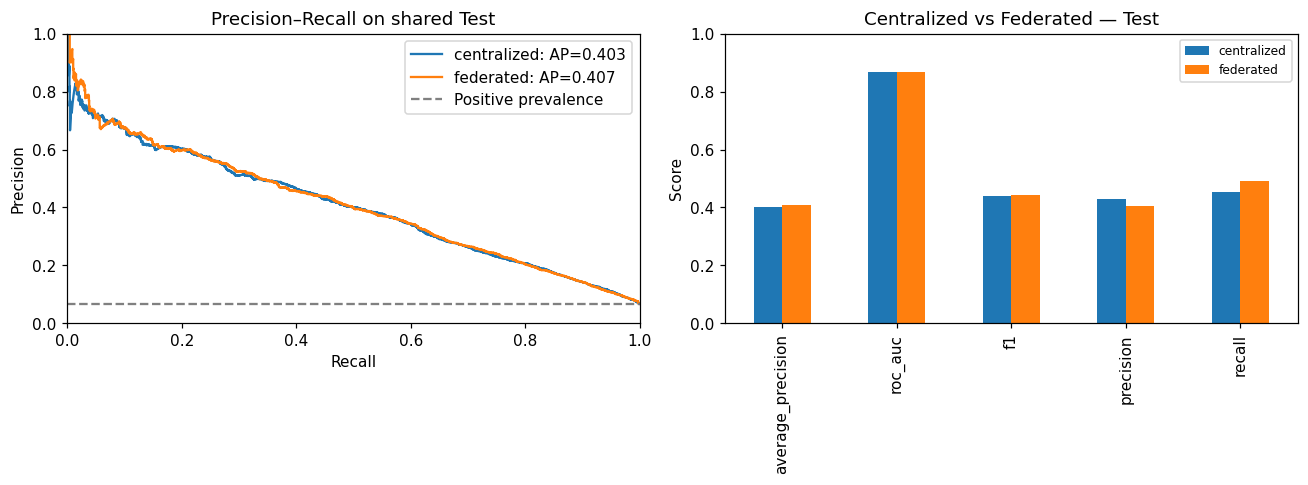

In [6]:
test_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, model in models.items():
    scores = probabilities(model, test)
    precision, recall, _ = precision_recall_curve(test[TARGET], scores)
    ap = average_precision_score(test[TARGET], scores)
    auc = roc_auc_score(test[TARGET], scores)
    axes[0].plot(recall, precision, label=f"{name}: AP={ap:.3f}")
    for policy, threshold in thresholds[name].items():
        test_rows.append({"model": name, "policy": policy, "average_precision": ap,
                          "roc_auc": auc, **metrics(test[TARGET], scores, threshold)})
results = pd.DataFrame(test_rows)
display(results.round(4))
axes[0].axhline(test[TARGET].mean(), linestyle="--", color="gray", label="Positive prevalence")
axes[0].set(title="Precision–Recall on shared Test", xlabel="Recall", ylabel="Precision", xlim=(0,1), ylim=(0,1))
axes[0].legend()
view = results[results.policy == "best_f1"].set_index("model")
view[["average_precision", "roc_auc", "f1", "precision", "recall"]].T.plot.bar(ax=axes[1])
axes[1].set(title="Centralized vs Federated — Test", ylabel="Score", ylim=(0,1))
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Lưu kết quả và giới hạn

Lưu manifest và metrics có thể kiểm chứng. Không coi numeric payload bytes là băng thông mạng; Azure/Flower deployment phải đo truyền thực tế, thời gian và lưu run ID riêng. FL ở đây ghép cây, không dùng FedAvg. Đây là mô phỏng từ một dataset tập trung, không chứng minh bảo mật tuyệt đối. Test có thể đã được dùng trong thí nghiệm cũ; cần tập độc lập để ước lượng hiệu năng triển khai.

In [7]:
run_id = f"seed{SEED}_{MODE}_clients{N_CLIENTS}_trees{TREES_PER_CLIENT}"
run_dir = RESULT_ROOT / run_id
run_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(run_dir / "test_metrics.csv", index=False)
pd.DataFrame(validation_rows).to_csv(run_dir / "validation_metrics.csv", index=False)
record = {"protocol": "v1.0", "run_id": run_id, "source_sha256": manifest["source_sha256"],
          "split_sha256": manifest["split_sha256"], "feature_schema_sha256": manifest["feature_schema_sha256"],
          "flower_schema_hash": schema_hash(features), "rf_config": RF_CONFIG,
          "central_trees": N_CLIENTS * TREES_PER_CLIENT, "client_trees": TREES_PER_CLIENT,
          "thresholds": thresholds, "client_log": client_log,
          "numeric_payload_bytes": payload_bytes, "central_train_seconds": central_seconds}
(run_dir / "run.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
print("Results:", run_dir)

Results: C:\Users\ACER\Documents\ChatGPT\Project Cloud\results\protocol_v1\seed42_iid_clients5_trees20
